**Privacy note:** Notebook outputs were cleared to avoid exposing dataset records. Configure source paths privately using environment variables.

#### Health Insurance Fraud Risk Assessment

#### Part 1: Objective 

#### This analysis evaluates whether a selected provider exhibits billing behaviour that significantly deviates from peers within the same specialty. The goal is to identify statistical signals that may indicate elevated fraud or overbilling risk.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import f1_score, recall_score, precision_score

In [ ]:
encounters = pd.read_csv(os.environ["ENCOUNTERS_DATA_PATH"])
claims = pd.read_csv(os.environ["CLAIMS_DATA_PATH"])
organizations = pd.read_csv(os.environ["ORGANIZATIONS_DATA_PATH"])
patients = pd.read_csv(os.environ["PATIENTS_DATA_PATH"])
providers = pd.read_csv(os.environ["PROVIDERS_DATA_PATH"])

### Claim Cost Deviation Analysis

#### Purpose 

To determine whether the target provider's average claim cost is significantly higher than the average cost among peer providers within the same specialty.

#### Key idea

We compare the target provider against a peer benchmark defined as: all general practice providers excluding the target provider

### Provider Identification and Context

The target provider is first retrieved to confirm their identity, speciality classification, and organizational affiliation. 

Verifying the provider's attributes ensures:
- Correct specialty-based peer benchmarking
- Accurate group inclusion for statistical comparison 
- Contextual understanding of organizational alignment

The information below establishes the provider profile used for subsequent analysis. 

In [ ]:
gp_provider = providers[providers['ID'] == "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]
gp_provider

### Benchmark Construction

Using general practice encounters: 
- The target provider claim costs are treated as the sample distribution of interest
- The peer provider claim costs (excluding the target) are used to compute a benchmark mean

This benchmark mean is used as the reference value in the hypothesis test

In [ ]:
gp_provider = providers[providers['SPECIALITY'] == 'GENERAL PRACTICE']['ID'].unique()
gp_encounters = encounters[encounters['PROVIDER'].isin(gp_provider)]

avg_claim_gp = gp_encounters[gp_encounters['PROVIDER'] == "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]['TOTAL_CLAIM_COST'].mean()
avg_claim_op = gp_encounters[gp_encounters['PROVIDER'] != "bb49afa2-3d8a-306c-a06e-a1715dd71af8"]['TOTAL_CLAIM_COST'].mean()

print(f"Average claim for general practice ${avg_claim_gp}")
print(f"Average claim for other providers ${avg_claim_op}")

### Provider Information Integration

To enable provider-level analysis within each encounter record, the encounters dataset is merged with the providers dataset. 

This step appends provider attributes (e.g name, specialty, gender, organization) to each encounter entry.

The enriched dataset allows:
- Specialty-based filtering
- Provider-level claim aggregation
- Peer group benchmarking

In [ ]:
df = pd.merge(encounters, providers, left_on='PROVIDER', right_on='ID', suffixes=(' ', '_y'))
df = df.loc[:, ~df.columns.str.endswith('_y')]
df.columns = df.columns.str.rstrip('_x')
df.head()

#### Overall General Practice Benchmark

Before isolating the target provider, we compute the overall average total claim cost across all providers within the General Practice specialty. 

This value serves as a high-level benchmark for contextual comparison against the target provider's claim behaviour. 

In [ ]:
avg_total_claim_gp = df[df['SPECIALITY'] == 'GENERAL PRACTICE']['TOTAL_CLAIM_COST'].mean()
avg_total_claim_gp

### Hypotheses

A one-sided one-sample t-test is conducted to evaluate whether the target provider's average total claim cost exceeds the peer benchmark mean. 

- Null Hypothesis: The target provider's mean total claim cost is less than or equal to the peer group mean.
- Alternative Hypothesis: The target provider's mean total claim cost is greater than the peer group mean. 

Significance level: 0.05

In [ ]:
provider_id = "bb49afa2-3d8a-306c-a06e-a1715dd71af8"
provider_info = providers.loc[providers['ID'] == provider_id]
gp_providers_ids = providers[providers['SPECIALITY'] == 'GENERAL PRACTICE']['ID']
specific_provider_claims = encounters[encounters['PROVIDER'] == provider_id]['TOTAL_CLAIM_COST']

other_gp_providers_claims = encounters[encounters['PROVIDER'].isin(gp_providers_ids) & (encounters['PROVIDER'] != provider_id)]['TOTAL_CLAIM_COST']

average_claim_cost_for_others = other_gp_providers_claims.mean()

specific_provider_claims.describe(), average_claim_cost_for_others

from scipy.stats import ttest_1samp

t_stat, p_value = ttest_1samp(specific_provider_claims, popmean=average_claim_cost_for_others, alternative='greater')

t_stat, p_value

### Interpretation (95% Confidence Level)

The one-sample t-test produced:
- t-statistic = 1.30
- p-value = 0.099

Since the p-value exceeds the significance level of 0.05, we fail to reject the null hypothesis. 

There is insufficient statistical evidence at the 95% confidence level to conclude that the target provider's mean total claim cost is greater than the peer benchmark mean. 

Although the provider's average appears numerically higher, the observed difference is not statistically significant under the chosen threshold. 

### Claim Cost Comparison between Organizations
- There are two organizations with similar profiles (types of patients seen, location etc.) for which we want to test whether the total claim costs between them are indeed similar as well. 
- The IDs of the two organizations are "226098a2-6a40-3588-b5bb-db56c3a30a04" and "108ccece-277a-396f-8bf2-1527f74458eb"

In [ ]:
org1_id = "226098a2-6a40-3588-b5bb-db56c3a30a04"
org2_id = "108ccece-277a-396f-8bf2-1527f74458eb"

In [ ]:
org1_claim_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST']
org2_claim_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST']

org1_avg_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST'].mean()
org2_avg_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST'].mean()

#### Claim Cost Extraction

Total claim costs are retrieved separately for each organization to construct two independent samples for comparison

In [ ]:
org_ids = [org1_id, org2_id]
org_details_df = organizations[organizations['ID'].isin(org_ids)]

org_details_df

#### Descriptive Comparison

The mean total claim cost is computed for each organization to provide an initial comparison prior to hypothesis testing

In [ ]:
org1_sum_costs = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST'].sum()
org2_sum_costs = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST'].sum()

print(f' Total claim costs for organization 1 is ${org1_sum_costs}')
print(f' Total claim costs for organization 2 is ${org2_sum_costs}')

#### Hypotheses (Two-tailed test)

- **H₀:** The mean total claim cost for Organization 1 equals that of Organization 2.
- **H₁:** The mean total claim cost for Organization 1 differs from that of Organization 2.

Significance level: α = 0.05

In [ ]:
org1_id = "226098a2-6a40-3588-b5bb-db56c3a30a04"
org2_id = "108ccece-277a-396f-8bf2-1527f74458eb"

org1_data = encounters[encounters['ORGANIZATION'] == org1_id]['TOTAL_CLAIM_COST']
org2_data = encounters[encounters['ORGANIZATION'] == org2_id]['TOTAL_CLAIM_COST']

# Check the size of the datasets for both organizations
org1_size = org1_data.size
org2_size = org2_data.size

from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(org1_data, org2_data, equal_var=True)

t_stat, p_value

#### Interpretation (95% Confidence Level)

The two-sample independent t-test resulted in a t-statistic of approximately 0.398 and a p-value of approximately 0.692.
The p-value indicates the probability of observing the test results under the null hypothesis, which in this context is that there is no difference in the mean total claim costs between the two organizations. A p-value of 0.692 is much higher than the common alpha level of 0.05, suggesting that we do not have enough evidence to reject the null hypothesis. Therefore, based on this analysis, it appears that there is no statistically significant difference in the mean total claim costs between the two organizations.

- At a 95% confidence level, the p-value is higher than the significance level of 0.05
- Therefore, we do not reject the null hypothesis, and conclude that the average total claim costs between the two organizations are similar

#### Multi-Organization Claim Cost Analysis

This section evaluates whether average total claim costs differ significantly across primary care practices (PCPs) located within selected cities.

The analysis focuses on organizations operating in the cities of AVON and WATERTOWN, with the goal of determining whether any organization exhibits a statistically distinct mean claim cost compared to others within this regional cohort. 

#### Organizational Claim Cost Extraction

Encounter-level data is enriched with organizational attributes (name and city) to enable grouping of total claim costs at the organization level.

This integratin allows construction of independent claim-cost samples for each organization within the selected cities. 

In [ ]:
merge_data = pd.merge(encounters,
                      organizations[['ID', 'NAME', 'CITY']],
                      left_on='ORGANIZATION',
                      right_on='ID',
                      how='left').drop(columns=['ID_y']).rename(columns={'ID_x': 'ID', 'NAME': 'ORGANIZATION_NAME', 'CITY': 'ORGANIZATION_CITY'})

merge_data

#### Regional Filtering
The dataset is filtered to include only organizations operating in AVON and WATERTOWN. This ensures that comparisons are made within a defined geographic context. 

In [ ]:
filtered_data = merge_data[(merge_data['ORGANIZATION_NAME'].str.contains("PCP")) & (merge_data['ORGANIZATION_CITY'].isin(["AVON", "WATERTOWN"]))]
filtered_data

In [ ]:
pcp_count = filtered_data['ORGANIZATION_NAME'].nunique()
pcp_names = filtered_data['ORGANIZATION_NAME'].unique()

pcp_count, pcp_names

#### Claim Cost Grouping by Organization

Total claim cost distributions are extracted separately for each organization within the selected cities. These independent samples will be used in a one-way ANOVA test.

In [ ]:
total_claim_cost_org = {name: group['TOTAL_CLAIM_COST'] for name, group in filtered_data.groupby('ORGANIZATION_NAME')}
list(total_claim_cost_org.keys())

### Hypotheses

- **Null Hypothesis (H₀):** All organizations within AVON and WATERTOWN have equal mean total claim costs.
- **Alternative Hypothesis (H₁):** At least one organization differs in mean total claim cost.

Significance level: α = 0.05

### Statistical Test

A one-way Analysis of Variance (ANOVA) is conducted using SciPy’s `f_oneway` function to determine whether between-organization variation exceeds within-organization variation.

In [ ]:
from scipy import stats
claim_cost_variables = list(total_claim_cost_org.values())
result = stats.f_oneway(*claim_cost_variables)
result

### Interpretation (95% Confidence Level)

If the p-value is less than 0.05, we reject the null hypothesis and conclude that at least one organization demonstrates a statistically significant difference in mean total claim cost.

If the p-value is greater than or equal to 0.05, we fail to reject the null hypothesis and conclude that observed variation in claim cost is not statistically significant across organizations within the selected cities.

### Business Implication

Significant variation across organizations may reflect institutional billing differences, operational structure, or patient case complexity.

If no statistical difference is detected, claim cost behavior appears consistent across organizations within AVON and WATERTOWN, suggesting no clear institutional outlier.

### Provider Encounter Mix Comparison
This section evaluates whether two selected providers differ in their encounter class composition (e.g. ambulatory, emergency, inpatient, outpatient)

While earlier sections focus on cost magnitude, encounter mix helps assess whether providers differ in the type of services delivered, which can explain or contextualize cost differences. 

#### Data Selection
- We restrict the encounters dataset to records associated with the two target providers. 
- This filtered subset serves as the basis for a provider-to-provider comparison of encounter class frequencies.

In [ ]:
provider_1_id = 'b0c5743a-4f9a-33b3-bab4-6a474fcf9ffd'
provider_2_id = 'fc897c25-b2ee-30c5-a945-d0eb13a1f96e'
provider_1 = encounters[encounters['PROVIDER'] == provider_1_id]
provider_2 = encounters[encounters['PROVIDER'] == provider_2_id]
filtered = encounters[encounters['PROVIDER'].isin([provider_1_id, provider_2_id])]
filtered_data = filtered[['ID', 'PROVIDER', 'ENCOUNTERCLASS']]
filtered_data

#### Hypotheses

- **Null Hypothesis (H₀):** The distribution of encounter categories is independent of provider identity.
- **Alternative Hypothesis (H₁):** The distribution of encounter categories differs between the two providers.

Significance level: α = 0.05

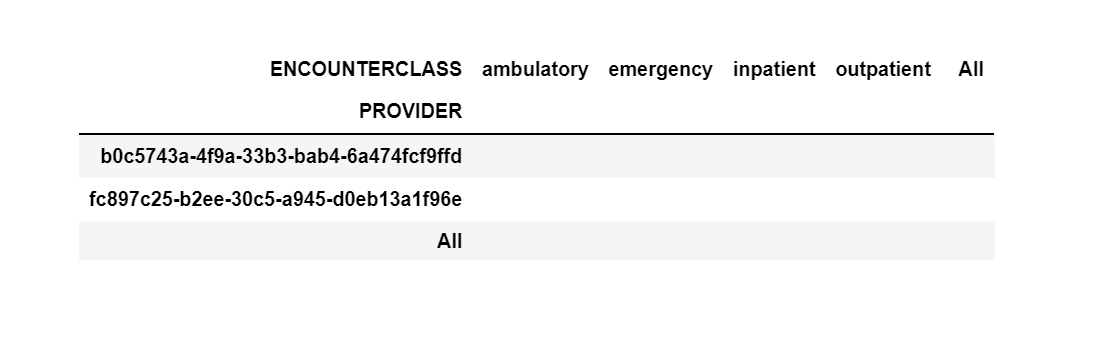

### Encounter Class Frequency Table

- A cross-tabulation table is constructed to summarize the count of encounters per encounter class for each provider.
- This provides the observed frequencies needed for a chi-square test of independence.

In [ ]:
df_crosstab = pd.crosstab(filtered_data['PROVIDER'], filtered_data['ENCOUNTERCLASS'], margins=True)
df_crosstab

To improve readability, the cross-tab labels are renamed to clearly indicate provider rows and encounter class columns

In [ ]:
# insert your code here:

df_crosstab.index = ['provider_1', 'provider_2', 'col_total']
df_crosstab.columns = ['ambulatory', 'emergency', 'inpatient', 'outpatient', 'row_total']
df_crosstab

### Contingency Table Construction

For hypothesis testing, the contingency table must exclude the row/column totals. 
The resulting 2xk table represents observed counts by provider (rows) and encounter class (columns).

In [ ]:
# insert your code here:

contingency_table = df_crosstab.iloc[:-1, :-1]
contingency_table

#### Hyptheses (Chi-square test of Independence)
- **Null Hypothesis (H₀):** Encounter class distribution is independent of provider identity  
  (i.e., both providers have the same encounter class proportions).

- **Alternative Hypothesis (H₁):** Encounter class distribution depends on provider identity  
  (i.e., at least one encounter class proportion differs between providers).

Significance level: α = 0.05

### Statistical Test
A chi-square test of independence is performed using `scipy.stats.chi2_contingency` on the contingency table. 
The test evaluates whether the observed differences in encounter class counts are larger than would be expected by chance.

In [ ]:
from scipy.stats import chi2_contingency
result = chi2_contingency(contingency_table)
result

#### Test Result
The p-value from the chi-square test is:
- **p-value:** 0.263

#### Interpretation (95% Confidence Level)

With **p = 0.263** and **α = 0.05**, we fail to reject the null hypothesis.

This indicates **insufficient statistical evidence** to claim that encounter class distributions differ between the two providers. Any observed differences in encounter mix may be attributable to sampling variability rather than systematic variation in practice patterns.

#### Part 2: The goal of this machine learning section is to build a binary classification model that predicts whether a health insurance claim will be "PAID" or "DENIED". The business objective is to reduce missed denied claims, as claims that should be denied but are incorrectly predicted as paid may result in unnecessary claim payouts and financial loss.

In [ ]:
encounters = encounters.rename(columns={"ID": "visit_id", "PATIENT": "patient_id", "PROVIDER": "provider_id", "ORGANIZATION": "healthcare_organization_id", "ENCOUNTERCLASS": "visit_type", "TOTAL_CLAIM_COST": "total_visit_claim_cost"})
encounters.isna().sum()

In [ ]:
claims = claims.rename(columns={"ID": "claims_id", "ENCOUNTER": "visit_id", "PATIENT": "patient_id", "PROVIDER": "provider_id", "ORGANIZATION": "healthcare_organization_id", "SERVICE_DATE": "service_date", "CLAIM_AMOUNT": "claim_amount", "STATUS": "claim_status"})
claims.isna().sum()

In [ ]:
organizations = organizations.rename(columns={"ID": "healthcare_organization_id", "NAME": "organization_name", "CITY": "organization_city", "STATE": "organization_state"})
organizations.isna().sum()

In [ ]:
patients = patients.rename(columns={"ID": "patients_id", "NAME": "patient_name", "GENDER": "patient_gender", "BIRTHDATE": "patient_birthdate", "CITY": "patient_city", "STATE": "patient_state"})
patients.isna().sum()

In [ ]:
providers = providers.rename(columns={"ID": "providers_id", "NAME": "providers_name", "SPECIALITY": "providers_speciality", "GENDER": "providers_gender", "ORGANIZATION": "healthcare_organization_id"})
providers.isna().sum()

#### Merge both encounters and claims data

In [ ]:
result = pd.merge(encounters, claims, on='visit_id', how='left')
result

#### Join patients tables together with encounters and claims data

In [ ]:
result_ = result.merge(patients, left_on='patient_id_y', right_on='patients_id', how='left')

#### Converting patient birthdate into age into numeric numbers for preprocessing

In [ ]:
result_['patient_birthdate'] = pd.to_datetime(result_['patient_birthdate'], errors='coerce')
result_['patient_age'] = (pd.Timestamp.today() - result_['patient_birthdate']).dt.days // 365

#### Filtering out claim status for both paid and denied claims and remove any assumptions for claims that is being adjusted or pending

In [ ]:
result_ = result_[(result_['claim_status'] == 'PAID') | (result_['claim_status'] == 'DENIED')] 

#### Unique Value Check

In [ ]:
result_.nunique()

In [ ]:
X = result_[['visit_type', 'total_visit_claim_cost', 'claim_amount', 'patient_gender', 'patient_age']]
y = result_['claim_status']

In [ ]:
category = ['visit_type', 'patient_gender']
numeric = ['total_visit_claim_cost', 'claim_amount', 'patient_age']

#### Checking on class imbalance

In [ ]:
(result_['claim_status'].value_counts(normalize=True) * 100.0).round(2)

#### One hot encoding

In [ ]:
preprocess = ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), category), ('num', 'passthrough', numeric)])

In [ ]:
model_rf = Pipeline([('preprocess', preprocess), ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))])
model_gb = Pipeline([('preprocess', preprocess), ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))])

#### The dataset is split into training, validation and test  sets using a 60/20/20 split. 

- Training data is used to fit the models.
- Validation data is used to compare models and tune the decision threshold
- Test data is reserved for final model evaluation

Stratified splitting is used to preserve the proportion of PAID and DENIED claims across all sets

In [ ]:
#60% train, 40% temp

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)

#Split temp into 20% val and 20% test

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [ ]:
print(len(X_train) / len(X))
print(len(X_val) / len(X))
print(len(X_test) / len(X))

#### Using train data to do model fitting into Random Forest Classifier and validation data to evaluate the model performance

In [ ]:
model_rf.fit(X_train, y_train)

y_pred_rf = model_rf.predict(X_val)

print(classification_report(y_val, y_pred_rf))

#### Using train data to do model fitting into Gradient Boosting and valdiation data to evaluate the model performance

In [ ]:
model_gb.fit(X_train, y_train)

y_pred_gb = model_gb.predict(X_val)

print(classification_report(y_val, y_pred_gb))

#### Based on the confusion matrix for random forest, we saw that 129 missing denied claims out of 247 total denied claims which may have a huge impact because close to 50% of the denied claims are not predicted as denied claims thus allowing the system to pay to the policyholders.

In [ ]:
cm_rf = confusion_matrix(y_val, y_pred_rf, labels=['DENIED', 'PAID'])
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['DENIED', 'PAID'])

disp_rf.plot()
plt.show()

#### Based on the confusion matrix, gradient boosting has a significantly higher of 145 missed denied claims than random forest. This creates a significant higher risk than random forest because of additional 16 more claims that is being passed while denied. 

In [ ]:
cm_gb = confusion_matrix(y_val, y_pred_gb, labels=['DENIED', 'PAID'])
disp_gb = ConfusionMatrixDisplay(confusion_matrix=cm_gb, display_labels=['DENIED', 'PAID'])

disp_gb.plot()
plt.show()

#### Threshold tuning was performed on the validation set to improve recall for the DENIED class. Since the business risk is mainly related to missed denied claims, the threshold was adjusted below the default 0.5 to classify more claims as DENIED. A threshold of 0.40 was selected because it improved recall for DENIED claims compared with the default threshold, although this may reduce precision and increase false positives. 

In [ ]:
denied_prob_gb = model_gb.predict_proba(X_val)[:, 0]
denied_prob_rf = model_rf.predict_proba(X_val)[:, 0]

thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4]

for threshold_gb in thresholds:
    y_pred_tuned_gb = np.where(denied_prob_gb >= threshold_gb, 'DENIED', 'PAID')

    print(f"\nThreshold_gb: {threshold_gb}")
    print(classification_report(y_val, y_pred_tuned_gb))

for threshold_rf in thresholds:
    y_pred_tuned_rf = np.where(denied_prob_rf >= threshold_rf, 'DENIED', 'PAID')

    print(f"\nThreshold_rf: {threshold_rf}")
    print(classification_report(y_val, y_pred_tuned_rf))



In [ ]:
print(f"\nThreshold_gb: {threshold_gb}")
print(f"\nThreshold_rf: {threshold_rf}")

#### After threshold tuning at 0.4, recall for the DENIED class improved, especially for Gradient Boosting. However, this came at the cost of lower precision and overall accuracy. This means the model is better at catching denied claims, but it also creates more false alarms.

In [ ]:
denied_prob_gb_test = model_gb.predict_proba(X_test)[:, 0]
denied_prob_rf_test = model_rf.predict_proba(X_test)[:, 0]

threshold_gb_rf = [0.4]

for threshold_gb_test in threshold_gb_rf:
    y_pred_test_gb = np.where(denied_prob_gb_test >= threshold_gb_test, 'DENIED', 'PAID')

for threshold_rf_test in threshold_gb_rf:
    y_pred_test_rf = np.where(denied_prob_rf_test >= threshold_rf_test, 'DENIED', 'PAID')


print(f"\nThreshold_gb: {threshold_gb}")
print(classification_report(y_test, y_pred_test_gb))
print(f"\nThreshold_rf: {threshold_rf}")
print(classification_report(y_test, y_pred_test_rf))

#### For random forest classification, total visit claim cost and claim amount used the most to predict the claim status. This helps to explain whether claim amount, visit type, patient age or patient gender had stronger influence on the model's predictions. 

In [ ]:
feature_names_rf = model_rf.named_steps['preprocess'].get_feature_names_out()
importances_rf = model_rf.named_steps['classifier'].feature_importances_

feature_importance_rf = pd.DataFrame({
    'feature': feature_names_rf,
    'importance': importances_rf
}).sort_values(by='importance', ascending=False)

feature_importance_rf

#### For gradient boosting, total visit claim cost and claim amount used the most to predict the claim status. This is very much similar to the feature importance shown in random forest classifier which total visit claim cost and claim amount had a higher influence on the model's predictions.

In [ ]:
feature_names_gb = model_gb.named_steps['preprocess'].get_feature_names_out()
importances_gb = model_gb.named_steps['classifier'].feature_importances_

feature_importance_gb = pd.DataFrame({
    'feature': feature_names_gb,
    'importance': importances_gb
}).sort_values(by='importance', ascending=False)

feature_importance_gb